# 01 · Python warm-up, file handling and NumPy

**Objective:** To refresh file I/O concepts and build a foundation in NumPy for advanced data manipulation.

## Part 0: Basic Concepts

How to access to jupyterlab?



### On your laptop

> **TODO 2026:** check these VM / Orfeo instructions (host names, IP address, users) against this year's setup.

Access the VM.

```ssh vm``` 

Then to install jupyterlab:

1) install the virtual environment for python ```apt install python3.12-venv```
2) change to user "ubuntu" with ```su ubuntu```
3) move back to your home with ```cd```
4) create a virtual environment ```python3 -m venv MDMC```
5) ```source ./MDMC/bin/activate```
6) ```pip install jupyterlab```
7) install the course packages: ```pip install -r requirements.txt``` (the file is in the course folder)

Now:

1) Access the VM, run the following code to start jupyter lab: ```jupyter lab --no-browser --ip "*"```
2) Go to your *local* terminal and "connect" to the VM running jupyter using ```ssh -L 8888:<vm-ip>:8888 -J orfeo root@<vm-ip>``` (or ``` ssh -L 8888:<vm-ip>:8888 -J <user-name>:195.14.102.215 root@<vm-ip>``` if you don't have defined ```orfeo```)
3) Copy and paste the jupyter url in a browser on your *local* computer.

### 0. Python Fundamentals Warm-up

Before diving into more advanced topics, let's quickly review the basic building blocks of Python code.

**Use the jupyter notebooks:** Blocks can be code or markdown, and you can run them either using the icons or by ```shift+enter``` combo.

**Defining a Function:** Functions are reusable blocks of code that perform a specific action. You define them using the `def` keyword.

In [4]:
def greet(name, surname="Deer", **kwargs):
    """This function greets the person passed in as a parameter."""
    if 'nickname' in kwargs.keys():
        return f"Hello, {name} {kwargs['nickname']} {surname}!"
    else:
        return f"Hello, {name} {surname}!"


In [5]:
help(greet)

Help on function greet in module __main__:

greet(name, surname='Deer', **kwargs)
    This function greets the person passed in as a parameter.



In [6]:
# Call the function
message = greet("World")
print(message)

# Call the function with optional inputs
message = greet("John", surname="Wick", nickname="Jr.")
print(message)

Hello, World Deer!
Hello, John Jr. Wick!


**Defining a Class:** Classes are blueprints for creating objects. They bundle data (attributes) and functions (methods) that work on that data.

In [7]:
class Dog:
    # The __init__ method is the constructor, run when an object is created
    def __init__(self, name, age):
        self.name = name  # Attribute
        self.age = age    # Attribute

    # A method
    def bark(self):
        return f"{self.name} says woof!"

# Create an instance (object) of the Dog class
my_dog = Dog("Rex", 5)
print(my_dog.name)
print(my_dog.bark())

Rex
Rex says woof!


**Importing a Module:** Modules are Python files with functions, classes, and variables that you can use in your own scripts. You use the `import` statement.

In [8]:
# Import the entire 'math' module
import math
print(math.sqrt(16)) # Use dot notation: module.function()

# Import a specific function from a module
from math import pi
print(pi)

# Import a module with an alias (a shorter name)
import numpy as np

# Modules also have methods
numbers = [0.1, 0.3, 0.5, 0.7]
numbers_np = np.array(numbers)
print(f"numbers is now a numpy array: {numbers_np}, its content sum up to {numbers_np.sum()}" )

4.0
3.141592653589793
numbers is now a numpy array: [0.1 0.3 0.5 0.7], its content sum up to 1.6


### 1. File I/O Review

We often need to read data from or write data to files. Python has robust built-in capabilities for this.

**Reading a `.txt` file:**

In [9]:
# First, let's create a file to read
with open('example.txt', 'w') as f:
    f.write("Hello from the file!\nThis is the second line.")

# Read all the file in one string
with open('example.txt', 'r') as f:
    content = f.read()
    print(content)
    
# Read all lines as a lis
with open('example.txt', 'r') as f:
    content = f.readlines()
    print(content)

Hello from the file!
This is the second line.
['Hello from the file!\n', 'This is the second line.']


**Reading a structured `.csv` file (using the `csv` module):**

In [ ]:
import csv

# Create a csv file to read
with open('data.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['name', 'age', 'city'])
    writer.writerow(['Alice', 30, 'New York'])
    writer.writerow(['Bob', 25, 'Los Angeles'])

with open('data.csv', 'r') as f:
    reader = csv.reader(f)
    for row in reader:
        print(row)

['name', 'age', 'city']
['Alice', '30', 'New York']
['Bob', '25', 'Los Angeles']


**Reading a structured `.json` file:**

In [17]:
import json

# Create a json file to read
data_to_write = {'name': 'Charlie', 'skills': ['python', 'data analysis']}
with open('data.json', 'w') as f:
    json.dump(data_to_write, f)

with open('data.json', 'r') as f:
    data = json.load(f)
    print(data)

{'name': 'Charlie', 'skills': ['python', 'data analysis']}


### Lab 1.1: Load JSON Data

* **Task:** Create a file named `products.json` with data about products. Write a Python script to load this JSON file and print the name of the second product.

In [ ]:
# Your code here


## Part 1: ```numpy```

### 2. The NumPy `ndarray`

NumPy's core object is the `ndarray` (n-dimensional array). It's faster and more memory-efficient than Python lists for numerical operations.

In [1]:
import numpy as np

# Create a 1D array from a list
list_a = [1, 2, 3, 4]
array_a = np.array(list_a)
print(f"1D Array: {array_a}")
print(f"Shape: {array_a.shape}")
print(f"Data type: {array_a.dtype}")

# Create a 2D array (matrix)
list_b = [[1, 2, 3], [4, 5, 6]]
array_b = np.array(list_b)
print(f"\n2D Array:\n{array_b}")
print(f"Shape: {array_b.shape}")

1D Array: [1 2 3 4]
Shape: (4,)
Data type: int64

2D Array:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)


#### (but why ```numpy```?)

In [2]:
long_list = [ i*0.1 for i in range(10000)]

def calculate_total_sum(nlist):
    tot = 0.
    for el in nlist:
        tot += el
    return tot

%timeit calculate_total_sum(long_list)


133 μs ± 6.17 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [5]:
long_list[0]

0.0

In [4]:
long_list_numpy = np.array(long_list)
%timeit long_list_numpy.sum()

2.29 μs ± 55.2 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


### 3. Advanced Indexing & Slicing

NumPy offers powerful ways to select data.

**Boolean Masking:** Use a boolean condition to filter the array.

In [7]:
arr = np.array([10, 20, 30, 40, 50])
# Select elements greater than 25
mask = (arr > 25) & (arr < 45)
print(f"Boolean Mask: {mask}")
print(f"Filtered Array: {arr[mask]}")

Boolean Mask: [False False  True  True False]
Filtered Array: [30 40]


**Fancy Indexing:** Use a list of indices to select specific elements.

In [10]:
arr = np.array([10, 20, 30, 40, 50, 60])
# Select the 1st, 3rd, and 4th elements
indices = [0, 2, 3]
print(f"Fancy Indexing: {arr[indices]}")

Fancy Indexing: [10 30 40]


### 4. Vectorization and Broadcasting

**Vectorization:** Operations are applied to entire arrays at once, element-by-element. This is much faster than using a Python `for` loop.

In [11]:
arr1 = np.array([1, 2, 3])
arr2 = np.array([10, 20, 30])

# Vectorized addition (no loop needed!)
result = arr1 + arr2 
print(f"Vectorized Sum: {result}")

Vectorized Sum: [11 22 33]


**Broadcasting:** NumPy's ability to perform operations on arrays of different (but compatible) shapes.

In [12]:
arr = np.array([[1, 2, 3], [4, 5, 6]])
scalar = 100

# The scalar is "broadcast" to each element
result = arr + scalar
print(f"Broadcasting result:\n{result}")

Broadcasting result:
[[101 102 103]
 [104 105 106]]


"When operating on two arrays, NumPy compares their shapes element-wise. It starts with the trailing (i.e. rightmost) dimension and works its way left. Two dimensions are compatible when

- they are equal, or
- one of them is 1.

Input arrays do not need to have the same number of dimensions. The resulting array will have the same number of dimensions as the input array with the greatest number of dimensions, where the size of each dimension is the largest size of the corresponding dimension among the input arrays. Note that missing dimensions are assumed to have size one."



 

In [13]:
# working
A = np.random.random(size=(8, 1, 6, 1))
B = np.random.random(size=(7, 1, 5))
print(f"the first result has shape: {(A * B).shape}")

# not working: trailing dimensions 6 and 5 are different and neither is 1
A = np.random.random(size=(8, 6))
B = np.random.random(size=(7, 5))
try:
    print(f"the result has shape: {(A * B).shape}")
except ValueError as e:
    print(f"ValueError: {e}")

the first result has shape: (8, 7, 6, 5)
ValueError: operands could not be broadcast together with shapes (8,6) (7,5) 


```
A      (4d array):  8 x 1 x 6 x 1
B      (3d array):      7 x 1 x 5
Result (4d array):  8 x 7 x 6 x 5
```

What happens in the additional dimensions? The values get repeated as necessary.

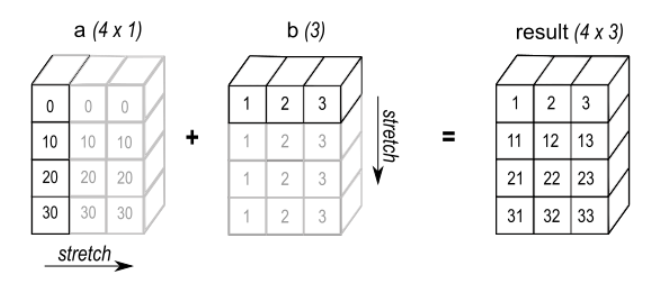

### 5. Mathematical and Statistical Functions

NumPy has a huge library of optimized functions. (like here: https://numpy.org/doc/stable/reference/routines.html )

In [14]:
data = np.array([10, 15, 22, 31, 50])

print(f"Sum: {np.sum(data)}")
print(f"Mean: {np.mean(data)}")
print(f"Standard Deviation: {np.std(data)}")
print(f"Max: {np.max(data)}")

Sum: 128
Mean: 25.6
Standard Deviation: 14.093970341958295
Max: 50


Very helpful built-in functions.

In [15]:
print(f"Shape: {data.shape}")

dims = (10,2,1)

init_to_zero = np.zeros(dims)

print("\n", init_to_zero, f"which has shape {init_to_zero.shape}")

Shape: (5,)

 [[[0.]
  [0.]]

 [[0.]
  [0.]]

 [[0.]
  [0.]]

 [[0.]
  [0.]]

 [[0.]
  [0.]]

 [[0.]
  [0.]]

 [[0.]
  [0.]]

 [[0.]
  [0.]]

 [[0.]
  [0.]]

 [[0.]
  [0.]]] which has shape (10, 2, 1)


A stand-alone method inside of numpy which is very relevant is ``` random```.

In [16]:
from numpy import random

print( f"Randint: {random.randint(low=0, high=5, size=(10,)) }")

print( f"Choice: {random.choice(['a', 'b', 'c'], size = 3)}" )

print( f"Random uniform: {random.random(size=(10,3))}")

print( f"Random normal distribution: {random.standard_normal(size=(2,3))}")

Randint: [3 1 2 1 4 0 2 3 2 3]
Choice: ['b' 'a' 'c']
Random uniform: [[0.59163417 0.52472659 0.33476515]
 [0.7952271  0.23783136 0.59752612]
 [0.43928135 0.58962077 0.67887779]
 [0.12536962 0.92723531 0.1697507 ]
 [0.73862533 0.67313611 0.39222082]
 [0.2864152  0.08566654 0.1113031 ]
 [0.71100677 0.67850009 0.9331621 ]
 [0.5244452  0.11974895 0.22911187]
 [0.74170164 0.97254864 0.97573311]
 [0.44280058 0.77494729 0.93616904]]
Random normal distribution: [[ 0.3593257   1.72618322 -0.60926885]
 [-0.80922555  0.11741339 -1.59577093]]


```numpy``` contains also all standard algebra operations, such as matrix multiplication, diagonalizations etc. etc.

In [17]:
A = random.standard_normal( size = (4,8) )
B = random.standard_normal( size = (8,3) )

print(f"A @ B: {np.matmul(A,B)}") 

# shorthand
print(f"A @ B: {A @ B}") 

print(f"transpose(A): {np.transpose(A)}")
print(f"transpose(A): {A.T}")

# A @ A.T is symmetric: use eigh, which returns real eigenvalues sorted in ascending order.
# (np.linalg.eig works for general matrices but may return complex numbers and does not sort.)
eigenvalues, eigenvectors = np.linalg.eigh( A @ A.T )

print(f"eigenvals: {eigenvalues}")
print(f"eigenvectors: {eigenvectors}")

A @ B: [[ 1.11989537  0.01541233 -0.11270756]
 [-0.4668071  -2.03284089 -0.05727205]
 [ 0.05068091 -0.85864774  0.19109855]
 [-1.27069367 -0.89205563 -2.17710011]]
A @ B: [[ 1.11989537  0.01541233 -0.11270756]
 [-0.4668071  -2.03284089 -0.05727205]
 [ 0.05068091 -0.85864774  0.19109855]
 [-1.27069367 -0.89205563 -2.17710011]]
transpose(A): [[ 0.53434859 -0.02666607 -0.51662006 -0.19383244]
 [ 0.78609186  1.16860267  1.19961399  1.04706419]
 [-1.42990641  0.48501392  0.73869289  0.71359797]
 [-0.51630897  0.43003616 -0.40031982 -1.10613577]
 [ 0.23112582 -1.02078575 -1.06263821  1.0429405 ]
 [ 0.55626935  0.17930662  0.99579269  0.5193592 ]
 [-0.28809273  0.44097415 -1.57417905 -1.11650082]
 [-0.05804462  0.53308286 -2.23982375 -0.56953753]]
transpose(A): [[ 0.53434859 -0.02666607 -0.51662006 -0.19383244]
 [ 0.78609186  1.16860267  1.19961399  1.04706419]
 [-1.42990641  0.48501392  0.73869289  0.71359797]
 [-0.51630897  0.43003616 -0.40031982 -1.10613577]
 [ 0.23112582 -1.02078575 -1.06

Some other important functions

In [18]:
print(f"Linear spacing, 10 points from 0 to 1 (included) {np.linspace(0,1,10)}")
print(f"Logarithmic spacing, 10 points from 10^0=1 to 10^1=10 (included) {np.logspace(0,1,10)}")

Linear spacing, 10 points from 0 to 1 (included) [0.         0.11111111 0.22222222 0.33333333 0.44444444 0.55555556
 0.66666667 0.77777778 0.88888889 1.        ]
Logarithmic spacing, 10 points from 10^0=1 to 10^1=10 (included) [ 1.          1.29154967  1.66810054  2.15443469  2.7825594   3.59381366
  4.64158883  5.9948425   7.74263683 10.        ]


## Exercises & Debugging

### Lab 1.2: Advanced NumPy Selection

* **Task:** Create a 2D NumPy array representing student grades. Use boolean masking to select all grades above 80. Then, use fancy indexing to select the grades of the 1st and 4th students (rows 0 and 3).

In [25]:
import numpy as np

grades = np.array([
    [85, 90, 78],
    [72, 65, 80],
    [95, 88, 92],
    [68, 75, 70],
    [88, 82, 91]
])

# Boolean masking
high_grades = grades[grades > 80]
print(f"Grades above 80: {high_grades}")

# Fancy indexing
selected_students = grades[[0,3]]
print(f"\nGrades for students 1 and 4:\n{selected_students}")


Grades above 80: [85 90 95 88 92 88 82 91]

Grades for students 1 and 4:
[[85 90 78]
 [72 65 80]
 [95 88 92]]


### Lab 1.3: (Advanced) Manual PCA with NumPy
* **Task:** Principal Component Analysis (PCA) is a technique to reduce the dimensionality of data. This exercise will guide you through the manual steps using NumPy's linear algebra capabilities.
* **Objective:** Understand how centering, covariance, and eigenvectors work together, and what each step actually *does* to the data.
* **Note:** here we only *center* the data (subtract the mean). If the columns had different units or scales, you would also divide by their standard deviation (*standardize*), which is equivalent to doing PCA on the correlation matrix instead of the covariance matrix.

#### The idea

Imagine a cloud of $n$ points in $d$ dimensions, stored as a matrix $X$ of shape $(n, d)$: one **row per point**, one **column per feature**. Often the points do not fill all $d$ dimensions: they are spread out along a few directions and almost flat along the others (think of a pancake floating in 3D: it is essentially 2D).

PCA answers the question: **which directions is the cloud most spread out along?** It builds a new set of orthogonal axes (the *principal components*) such that

* axis 1 points along the direction of **largest variance**,
* axis 2 along the largest variance among the directions **orthogonal** to axis 1,
* and so on.

Geometrically, the whole procedure is just **a translation followed by a rotation** of the coordinate system. No point is moved relative to the others: we are only choosing better axes to describe them. Dimensionality reduction comes at the very end, when we decide to *drop* the axes along which the cloud is (almost) flat.

#### The mathematics, step by step

**Step 1: centering (translation).** Subtract the mean of each column, $\bar{\mathbf{x}} = \frac{1}{n}\sum_i \mathbf{x}_i$:
$$\tilde{X} = X - \bar{\mathbf{x}} .$$
This moves the origin to the centre of the cloud. Variance is measured around the mean, so the directions we look for must pass through it.

**Step 2: covariance matrix.** For centered data the $d \times d$ covariance matrix is
$$C = \frac{1}{n-1}\,\tilde{X}^\top \tilde{X}, \qquad C_{jk} = \frac{1}{n-1}\sum_i \tilde{x}_{ij}\,\tilde{x}_{ik} .$$
On the diagonal, $C_{jj}$ is the variance of feature $j$. Off the diagonal, $C_{jk}$ measures how much features $j$ and $k$ vary together. $C$ is **symmetric** ($C_{jk} = C_{kj}$).

**Why $C$ is the right object.** Take any direction, i.e. a unit vector $\mathbf{w}$ ($\|\mathbf{w}\| = 1$). The coordinate of each point along it is the dot product $\tilde{\mathbf{x}}_i \cdot \mathbf{w}$, so all the coordinates together are $\tilde{X}\mathbf{w}$. The variance of the cloud along $\mathbf{w}$ is
$$\operatorname{Var}(\mathbf{w}) = \frac{1}{n-1}\,\|\tilde{X}\mathbf{w}\|^2 = \mathbf{w}^\top C\, \mathbf{w} .$$
So **$C$ knows the variance along every possible direction**, not just along the original axes.

**Step 3: why eigenvectors?** We want the direction with the largest variance: maximise $\mathbf{w}^\top C \mathbf{w}$ subject to $\mathbf{w}^\top \mathbf{w} = 1$. With a Lagrange multiplier $\lambda$, set the gradient of $\mathbf{w}^\top C \mathbf{w} - \lambda(\mathbf{w}^\top\mathbf{w} - 1)$ to zero:
$$2C\mathbf{w} - 2\lambda \mathbf{w} = 0 \quad\Longrightarrow\quad C\mathbf{w} = \lambda \mathbf{w} .$$
**The best direction must be an eigenvector of $C$!** Multiplying on the left by $\mathbf{w}^\top$ also gives $\operatorname{Var}(\mathbf{w}) = \mathbf{w}^\top C \mathbf{w} = \lambda$: **the eigenvalue is the variance along its eigenvector.** The maximum is therefore the eigenvector with the *largest* eigenvalue. Repeating the argument with the extra constraint of being orthogonal to the previous directions gives the eigenvector with the second largest eigenvalue, and so on.

Because $C$ is symmetric, the *spectral theorem* guarantees that its eigenvalues are real (and here $\geq 0$, being variances) and that its eigenvectors can be chosen **orthonormal**. Stacking them as columns of $V$ (sorted by decreasing eigenvalue):
$$C = V \Lambda V^\top, \qquad \Lambda = \operatorname{diag}(\lambda_1 \geq \lambda_2 \geq \dots \geq \lambda_d), \qquad V^\top V = I .$$
`np.linalg.eigh` is NumPy's routine for symmetric matrices: it uses this structure and is faster and more accurate than the general `np.linalg.eig`.

**Step 4: projection (rotation).** The new coordinates of the points are
$$Z = \tilde{X} V .$$
Since $V$ is orthogonal, this is a rotation (possibly with reflections): distances and angles between points are preserved. In the new coordinates, the covariance is
$$C_Z = \frac{1}{n-1} Z^\top Z = V^\top C\, V = \Lambda ,$$
which is **diagonal**: the principal components are **uncorrelated**, and the variance along component $k$ is exactly $\lambda_k$.

**Step 5: explained variance.** A rotation does not change the total variance, $\sum_j C_{jj} = \operatorname{tr}(C) = \sum_k \lambda_k$. So the fraction of the total variance carried by component $k$ is
$$r_k = \frac{\lambda_k}{\sum_{j} \lambda_j} .$$

**Dimensionality reduction.** Keeping only the first $m$ columns of $V$ (call them $V_m$) gives an $(n, m)$ representation $Z_m = \tilde{X} V_m$. Going back to the original space, $\hat{X} = Z_m V_m^\top + \bar{\mathbf{x}}$, the average squared error is exactly the sum of the discarded eigenvalues. If those are tiny, we lose almost nothing.

#### What to expect with our data

The function below builds a Gaussian cloud with 3 independent directions of standard deviations $\sigma_1, \sigma_2, \sigma_3$ (`intrinsic_stds`), **rotates it at random into 10 dimensions**, and adds a little noise of standard deviation $\sigma_\text{noise}$ in every direction. PCA should undo that hidden rotation: we expect 3 large eigenvalues $\lambda_k \approx \sigma_k^2$, and 7 tiny ones $\approx \sigma_\text{noise}^2$.

In [26]:
# Function to generate a Gaussian Cloud of points which lives in 3D inside a 10D world.
# Do now worry about what this function does... only that it produces a nice cloud of points!

def generate_rotated_gaussian_cloud(
    n_points=200,
    intrinsic_stds=[0.7, 0.25, 0.15],
    embedding_dim=10,
    noise_level=0.01
):
    """
    Generates a Gaussian point cloud with a low intrinsic dimensionality
    randomly rotated within a higher-dimensional embedding space.

    Args:
        n_points (int): The number of points to generate.
        intrinsic_stds (list or np.array): A list of standard deviations ("sizes")
                                            for the core intrinsic dimensions.
        embedding_dim (int): The final dimensionality of the embedding space.
        noise_level (float): The standard deviation of the small isotropic noise
                             added to all dimensions.

    Returns:
        np.ndarray: An array of shape (n_points, embedding_dim) containing the data.
    """
    intrinsic_dim = len(intrinsic_stds)

    # 1. Generate the core data in its native low-dimensional space
    # Shape: (n_points, intrinsic_dim) -> (1000, 3)
    points_3d = np.random.randn(n_points, intrinsic_dim) * intrinsic_stds

    # 2. Create a random rotation matrix to embed the 3D space into 10D
    # We generate a random 10x10 matrix and use QR decomposition to get
    # a random orthogonal matrix (a rotation).
    # See: https://en.wikipedia.org/wiki/Orthogonal_matrix#Randomization
    random_matrix = np.random.randn(embedding_dim, embedding_dim)
    q, _ = np.linalg.qr(random_matrix)

    # The first 3 columns of Q form an orthonormal basis for a random 3D subspace
    rotation_matrix = q[:, :intrinsic_dim] # Shape: (10, 3)

    # 3. Project the 3D points into the 10D space
    # (1000, 3) @ (3, 10) -> (1000, 10)
    points_10d = points_3d @ rotation_matrix.T

    # 4. Add a small amount of isotropic noise to all 10 dimensions
    noise = np.random.randn(n_points, embedding_dim) * noise_level
    final_points = points_10d + noise

    return final_points


In [27]:
# 0. Our original data
data = generate_rotated_gaussian_cloud(
    n_points=1000,
    intrinsic_stds=[0.6, 0.25, 0.15],
    embedding_dim=10,
    noise_level=0.01
)
print("Data has shape:", data.shape)


Data has shape: (1000, 10)


In [28]:

# Step 1: Center the data: for each column, subtract its mean.
#         X_tilde = X - mean
centered_data =  data - np.mean(data, axis=0)

# Step 2: Calculate the covariance matrix (it should be 10 x 10).
#         C = X_tilde^T X_tilde / (n - 1)
# USE np.cov! BE CAREFUL: by default np.cov treats each ROW as a variable.
cov_matrix = np.cov(centered_data, rowvar=False)

# Step 3: Compute eigenvalues and eigenvectors: C v = lambda v.
# The covariance matrix is symmetric, so use np.linalg.eigh. It returns the
# eigenvalues in ASCENDING order: sort them in DESCENDING order, and reorder
# the columns of the eigenvector matrix in the same way.
# (Eigenvector k is the COLUMN eigenvectors[:, k], not the row!)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
# Sort eigenvalues and eigenvectors in descending order
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Step 4: Project the centered data onto the principal components (rotation).
#         Z = X_tilde @ V   -> shape (1000, 10)
projected_data = centered_data @ eigenvectors

# Step 5: Explained variance ratio of each component:
#         r_k = lambda_k / (sum of all eigenvalues).
explained_variance = eigenvalues / np.sum(eigenvalues)

#### Checking the mathematics numerically

Let's verify the claims above on our data. Each line below corresponds to one equation from the theory section.

In [29]:
# (a) Our covariance matrix is X_tilde^T X_tilde / (n - 1)
n = centered_data.shape[0]
print("C == X^T X / (n-1)?        ", np.allclose(cov_matrix, centered_data.T @ centered_data / (n - 1)))

# (b) The eigenvectors are orthonormal: V^T V = I  (so Z = X V is a rotation)
print("V^T V == I?                ", np.allclose(eigenvectors.T @ eigenvectors, np.eye(len(eigenvalues))))

# (c) In the new coordinates the covariance is diagonal, with the eigenvalues on the diagonal
cov_projected = np.cov(projected_data, rowvar=False)
print("Cov(Z) == diag(lambda)?    ", np.allclose(cov_projected, np.diag(eigenvalues)))

# (d) The rotation preserves the total variance: trace(C) == sum of eigenvalues
print("trace(C) == sum(lambda)?   ", np.isclose(np.trace(cov_matrix), eigenvalues.sum()))

# (e) Eigenvalues vs. the parameters of the generator
print("\nEigenvalues (variances along each component):", np.round(eigenvalues, 4))
print("intrinsic_stds**2:", np.array([0.6, 0.25, 0.15])**2, "  noise_level**2:", 0.01**2)

# (f) Keep only m = 3 components, go back to 10D, and measure what we lost
m = 3
V_m = eigenvectors[:, :m]
reconstructed = projected_data[:, :m] @ V_m.T + data.mean(axis=0)
mse = np.sum((data - reconstructed)**2) / (n - 1)
print(f"\nReconstruction error with {m} components:", round(mse, 6),
      "  sum of discarded eigenvalues:", round(eigenvalues[m:].sum(), 6))

C == X^T X / (n-1)?         True
V^T V == I?                 True
Cov(Z) == diag(lambda)?     True
trace(C) == sum(lambda)?    True

Eigenvalues (variances along each component): [3.857e-01 6.280e-02 2.170e-02 1.000e-04 1.000e-04 1.000e-04 1.000e-04
 1.000e-04 1.000e-04 1.000e-04]
intrinsic_stds**2: [0.36   0.0625 0.0225]   noise_level**2: 0.0001

Reconstruction error with 3 components: 0.000703   sum of discarded eigenvalues: 0.000703


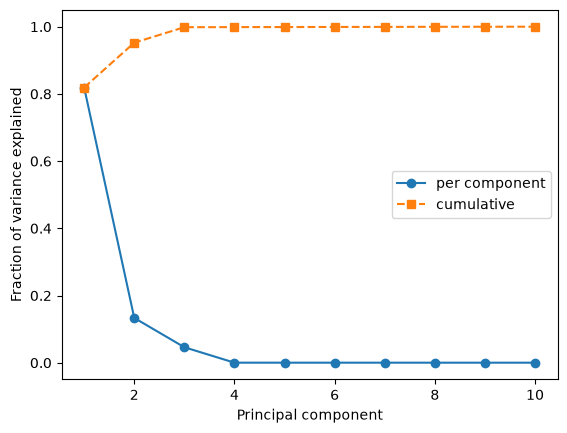

In [30]:
import matplotlib.pyplot as plt

components = np.arange(1, len(explained_variance) + 1)
fig, ax = plt.subplots()
ax.plot(components, explained_variance, "o-", label="per component")
ax.plot(components, np.cumsum(explained_variance), "s--", label="cumulative")
ax.set_xlabel("Principal component")
ax.set_ylabel("Fraction of variance explained")
ax.legend()
plt.show()

**Questions:**
1. How many components do you need to explain 99% of the variance? Compare with the number of intrinsic dimensions used to generate the data.
2. How do the variances of the first components relate to the `intrinsic_stds` passed to the generator?
3. Increase `noise_level` to 0.1. What changes in the plot?
4. Run the eigendecomposition twice on slightly different data: some eigenvectors may come out with the opposite sign. Why is this not a problem? (*Hint:* if $C\mathbf{v} = \lambda\mathbf{v}$, what about $-\mathbf{v}$?)